# HF subword TF-IDF + LogReg C=16 Gutenberg-weighted

## Setup & config

In [1]:
import os, re, gc, time, socket, warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, FileLink
from joblib import Parallel, delayed

from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# ---------------- config ----------------
RANDOM_STATE        = 42
VAL_N               = 20_000     # identical validation split to the other notebooks
FINAL_N             = 150_000    # stratified training rows (None = all remaining rows; more RAM/time)
INCLUDE_ALL_GUT     = True       # add every Gutenberg row from the pool to the training set
GUT_WEIGHT          = 2.0        # sample weight for all Gutenberg rows
GUT_MINORITY_WEIGHT = 4.0        # extra multiplier for Gutenberg human/fusion (total 8x vs a normal row)
C                   = 16         # best LogReg C from the search
MAX_ITER            = 1000
HF_TOKENIZER        = "FacebookAI/xlm-roberta-base"
N_JOBS              = os.cpu_count() or 2

TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
LANGS = ["en-EN", "de-DE"]
GUT = "gutenberg"

@contextmanager
def timer(msg):
    t0 = time.time()
    print(f"[start] {msg} ...", flush=True)
    yield
    print(f"[done]  {msg}: {time.time() - t0:.1f}s", flush=True)

## Load data

In [2]:
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"

def find_data_dir():
    for root in [Path("/kaggle/input"), Path("data"), Path("../data")]:
        if root.exists():
            hits = sorted(root.rglob("train.csv"))
            hits = [h for h in hits if COMP in str(h)] or hits
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found: add the competition data as an input")

DATA_DIR = find_data_dir()
with timer("read csv"):
    train = pd.read_csv(DATA_DIR / "train.csv")
    test = pd.read_csv(DATA_DIR / "test.csv")
    sample_sub = pd.read_csv(next(iter(sorted(DATA_DIR.glob("sample_submission*.csv")))))
for df in (train, test):
    df[TEXT] = df[TEXT].fillna("").astype(str)
print(f"data dir: {DATA_DIR} | train {train.shape} | test {test.shape}")

[start] read csv ...
[done]  read csv: 21.9s
data dir: /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026 | train (272352, 5) | test (25000, 4)


## Splits and Gutenberg-weighted training set

In [3]:
strat = train[LABEL] + "|" + train[LANG] + "|" + train[DOMAIN]
pool_idx, val_idx = train_test_split(train.index, test_size=VAL_N, stratify=strat, random_state=RANDOM_STATE)
pool, val = train.loc[pool_idx], train.loc[val_idx]

def strat_sample(df, n, seed=RANDOM_STATE):
    if n is None or n >= len(df):
        return df
    s = df[LABEL] + "|" + df[LANG] + "|" + df[DOMAIN]
    keep, _ = train_test_split(df.index, train_size=n, stratify=s, random_state=seed)
    return df.loc[keep]

final_tr = strat_sample(pool, FINAL_N)
if INCLUDE_ALL_GUT:
    extra = pool[(pool[DOMAIN] == GUT) & ~pool.index.isin(final_tr.index)]
    final_tr = pd.concat([final_tr, extra])
    print(f"added {len(extra):,} extra Gutenberg rows")
del pool; gc.collect()

is_gut = (final_tr[DOMAIN] == GUT).values
minority = np.isin(final_tr[LABEL].values, ["human", "fusion"])
weights = np.where(is_gut, GUT_WEIGHT, 1.0) * np.where(is_gut & minority, GUT_MINORITY_WEIGHT, 1.0)
weights = weights / weights.mean()          # mean 1 -> C keeps its meaning

print(f"train rows: {len(final_tr):,} | val rows: {len(val):,}")
summary = (final_tr.assign(w=weights, domain_group=np.where(is_gut, "gutenberg", "other"))
           .groupby(["domain_group", LABEL]).agg(rows=("w", "size"), weight_per_row=("w", "mean"), total_weight=("w", "sum")))
display(summary.round(2))

added 2,760 extra Gutenberg rows
train rows: 152,760 | val rows: 20,000


rows  weight_per_row  total_weight
domain_group label                                      
gutenberg    ai       6226            1.87      11666.95
             fusion    350            7.50       2623.47
             human     229            7.50       1716.50
other        ai      63460            0.94      59459.08
             fusion  45879            0.94      42986.50
             human   36616            0.94      34307.50

## HF subword tokenizer (open-weight, from Hugging Face)
Loads `xlm-roberta-base`'s SentencePiece tokenizer, either from a Kaggle input that contains the tokenizer files or from the Hub. Only the tokenizer is used, not the model weights.

In [4]:
def internet_ok(host="huggingface.co", port=443, timeout=3):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

def find_local_tokenizer():
    root = Path("/kaggle/input")
    if root.exists():
        for f in sorted(root.rglob("tokenizer.json")) + sorted(root.rglob("sentencepiece.bpe.model")):
            if "xlm-roberta" in str(f).lower() or "xlm_roberta" in str(f).lower():
                return str(f.parent)
    return None

from transformers import AutoTokenizer
TOK_SRC = find_local_tokenizer()
if TOK_SRC is None:
    if not internet_ok():
        raise RuntimeError("This notebook needs the xlm-roberta-base tokenizer: turn on Settings -> Internet "
                           "or attach the tokenizer files as an input.")
    TOK_SRC = HF_TOKENIZER
HF_TOK = AutoTokenizer.from_pretrained(TOK_SRC)
HF_TOK.model_max_length = 10**9
print(f"tokenizer from {TOK_SRC} | vocab={HF_TOK.vocab_size:,} | example:",
      HF_TOK.tokenize("Die Bundesregierung muss handeln, delve into it")[:14])

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

tokenizer from FacebookAI/xlm-roberta-base | vocab=250,002 | example: ['▁Die', '▁Bundesregierung', '▁muss', '▁handel', 'n', ',', '▁del', 've', '▁into', '▁it']


## Features: TF-IDF over subword-id 1–2-grams
Each text becomes its sequence of token ids. The ids are hashed into 2^20 columns (unigrams + bigrams), then TF-IDF with sublinear term frequency and L2 normalisation.

In [5]:
HASHER = HashingVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False, token_pattern=r"\S+",
                           n_features=2**20, alternate_sign=False, norm=None, dtype=np.float32)

def token_strings(texts, batch=2000):
    texts = list(texts)
    out = []
    for i in range(0, len(texts), batch):
        ids = HF_TOK(texts[i:i + batch], add_special_tokens=False, verbose=False)["input_ids"]
        out.extend(" ".join(map(str, x)) for x in ids)
    return out

def hashed(texts, chunk=4000):
    toks = token_strings(texts)
    parts = Parallel(n_jobs=N_JOBS)(delayed(HASHER.transform)(toks[i:i + chunk]) for i in range(0, len(toks), chunk))
    return sp.vstack(parts).tocsr()

tfidf = TfidfTransformer(sublinear_tf=True)
with timer(f"features train ({len(final_tr):,} rows)"):
    X_tr = tfidf.fit_transform(hashed(final_tr[TEXT])).astype(np.float32).tocsr()
with timer("features val + test"):
    X_val = tfidf.transform(hashed(val[TEXT])).astype(np.float32).tocsr()
    X_test = tfidf.transform(hashed(test[TEXT])).astype(np.float32).tocsr()
print(f"X_tr {X_tr.shape}, nnz/doc={X_tr.nnz / X_tr.shape[0]:.0f}")

[start] features train (152,760 rows) ...
[done]  features train (152,760 rows): 284.6s
[start] features val + test ...
[done]  features val + test: 83.4s
X_tr (152760, 1048576), nnz/doc=960


## Fit the model: LogisticRegression(C=16) with Gutenberg sample weights

In [6]:
with timer(f"fit LogisticRegression(C={C})"):
    model = LogisticRegression(C=C, max_iter=MAX_ITER)
    model.fit(X_tr, final_tr[LABEL].values, sample_weight=weights)
print("iterations:", model.n_iter_)
del X_tr; gc.collect()

val_proba = model.predict_proba(X_val)
val_pred = model.classes_[val_proba.argmax(1)]
y_val = val[LABEL].values
v = val.assign(pred=val_pred, correct=val_pred == y_val, n_chars=val[TEXT].str.len())

[start] fit LogisticRegression(C=16) ...
[done]  fit LogisticRegression(C=16): 733.0s
iterations: [146]


## Overall per-class metrics

Validation (20,000 rows) | macro-F1 = 0.8846 | accuracy = 0.9033

              precision    recall  f1-score   support

       human     0.8038    0.8388    0.8209      4900
          ai     0.9883    0.9908    0.9896      8954
      fusion     0.8602    0.8272    0.8434      6146

    accuracy                         0.9033     20000
   macro avg     0.8841    0.8856    0.8846     20000
weighted avg     0.9038    0.9033    0.9033     20000



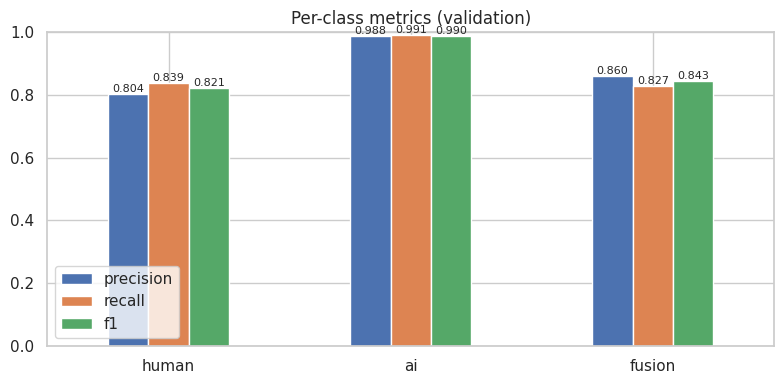

In [7]:
VAL_MACRO_F1 = f1_score(y_val, val_pred, average="macro")
print(f"Validation ({len(val):,} rows) | macro-F1 = {VAL_MACRO_F1:.4f} | accuracy = {accuracy_score(y_val, val_pred):.4f}\n")
print(classification_report(y_val, val_pred, labels=CLASSES, digits=4))

p, r, f, s = precision_recall_fscore_support(y_val, val_pred, labels=CLASSES)
ax = pd.DataFrame({"precision": p, "recall": r, "f1": f}, index=CLASSES).plot.bar(rot=0, figsize=(8, 4), ylim=(0, 1),
                                                                                  title="Per-class metrics (validation)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()

## Confusion matrices

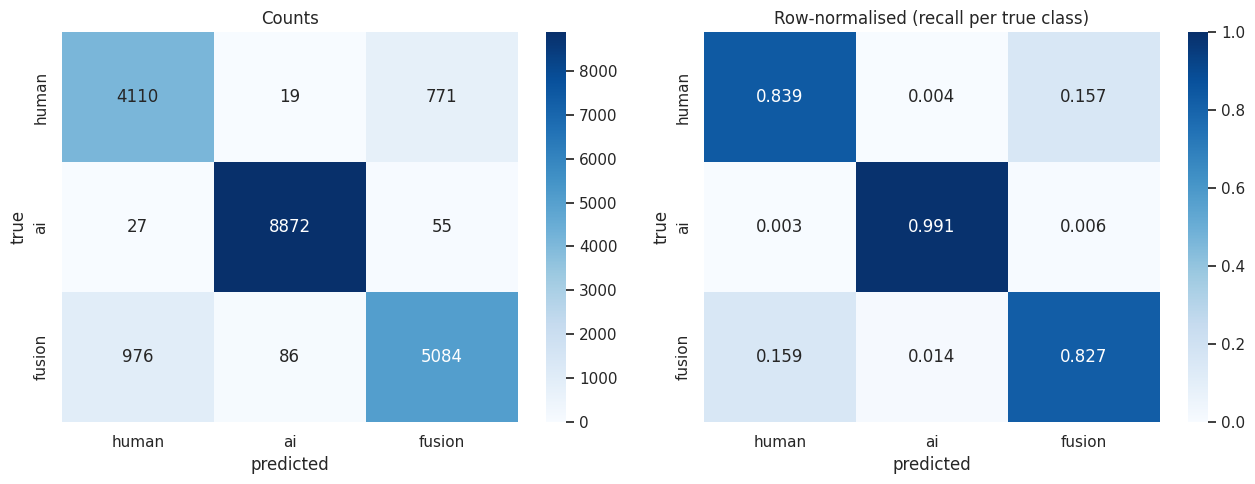

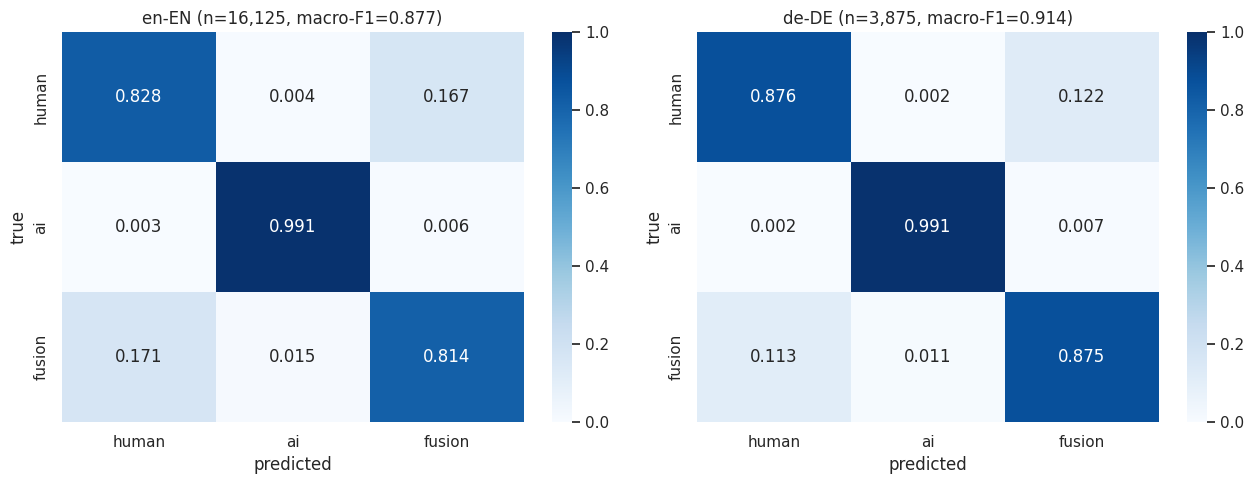

In [8]:
def cm_plot(y_true, y_pred, title, ax, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    data = cm / np.maximum(cm.sum(1, keepdims=True), 1) if normalize else cm
    sns.heatmap(data, annot=True, fmt=".3f" if normalize else "d", cmap="Blues", vmin=0, vmax=1 if normalize else None,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(title); ax.set_xlabel("predicted"); ax.set_ylabel("true")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_plot(y_val, val_pred, "Counts", axes[0], normalize=False)
cm_plot(y_val, val_pred, "Row-normalised (recall per true class)", axes[1])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(LANGS), figsize=(13, 5))
for ax, lang in zip(axes, LANGS):
    m = (v[LANG] == lang).values
    cm_plot(y_val[m], val_pred[m], f"{lang} (n={m.sum():,}, macro-F1={f1_score(y_val[m], val_pred[m], average='macro'):.3f})", ax)
plt.tight_layout(); plt.show()

## Where does it fail? Language × domain

,lang,domain,n,n_human,n_ai,n_fusion,macro_f1,accuracy,f1_human,f1_ai,f1_fusion
6,en-EN,gutenberg,508,16,467,25,0.570,0.947,0.258,0.995,0.458
3,en-EN,blog_authorship_corpus,2977,915,1152,910,0.750,0.768,0.661,0.963,0.625
2,en-EN,arxiv_papers,1050,30,885,135,0.879,0.982,0.710,0.999,0.929
7,en-EN,house_of_commons,2340,511,1123,706,0.902,0.923,0.843,0.991,0.872
8,en-EN,student_essays,3973,918,1585,1470,0.903,0.915,0.834,0.991,0.886
0,de-DE,bundestag,3844,1063,1467,1314,0.914,0.920,0.868,0.990,0.883
5,en-EN,euro_court_cases,2025,461,818,746,0.915,0.927,0.848,0.997,0.901
4,en-EN,cnn_news,3252,984,1431,837,0.918,0.931,0.895,0.997,0.861
1,de-DE,gutenberg,31,2,26,3,1.000,1.000,1.000,1.000,1.000


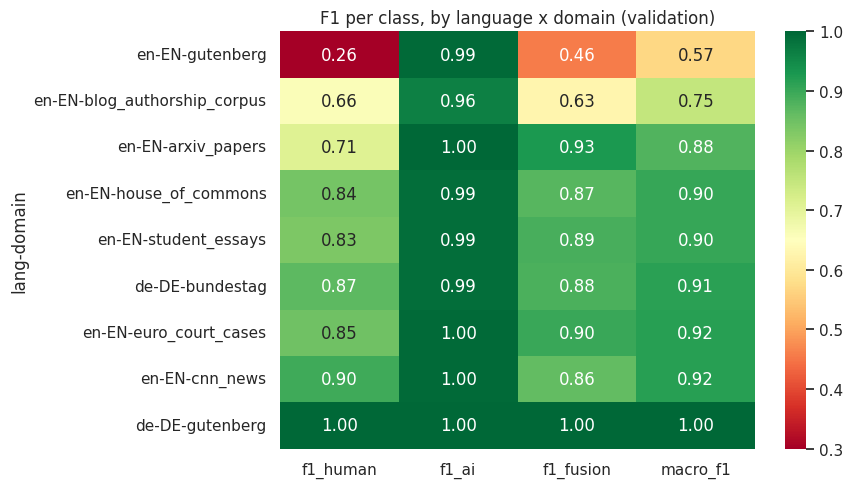

In [9]:
rows = []
for (lang, dom), gr in v.groupby([LANG, DOMAIN]):
    f1s = f1_score(gr[LABEL], gr["pred"], labels=CLASSES, average=None, zero_division=0)
    rows.append({"lang": lang, "domain": dom, "n": len(gr),
                 **{f"n_{c}": int((gr[LABEL] == c).sum()) for c in CLASSES},
                 "macro_f1": f1_score(gr[LABEL], gr["pred"], average="macro", zero_division=0),
                 "accuracy": gr["correct"].mean(), **{f"f1_{c}": x for c, x in zip(CLASSES, f1s)}})
by_dom = pd.DataFrame(rows).sort_values("macro_f1")
display(by_dom.style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="RdYlGn", vmin=0.3, vmax=1)
        .format(precision=3))

plt.figure(figsize=(9, 0.45 * len(by_dom) + 1))
sns.heatmap(by_dom.set_index(["lang", "domain"])[["f1_human", "f1_ai", "f1_fusion", "macro_f1"]],
            annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.3, vmax=1)
plt.title("F1 per class, by language x domain (validation)"); plt.tight_layout(); plt.show()

## Gutenberg deep-dive
How the weighted model does on Gutenberg. With only 18 human and 28 fusion validation rows here, a single text moves F1 by several points: read these numbers as a direction, not a precise score.

Gutenberg validation rows: 539 | labels: {'ai': 493, 'fusion': 28, 'human': 18}
Gutenberg macro-F1 = 0.6188

              precision    recall  f1-score   support

       human      0.353     0.333     0.343        18
          ai      0.992     0.998     0.995       493
      fusion      0.538     0.500     0.519        28

    accuracy                          0.950       539
   macro avg      0.628     0.610     0.619       539
weighted avg      0.947     0.950     0.948       539



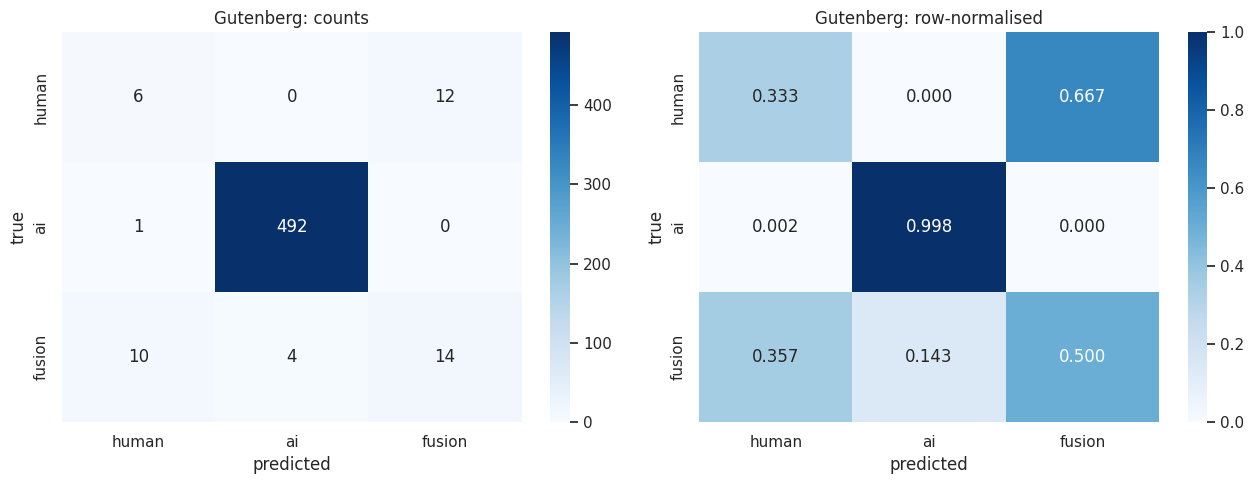

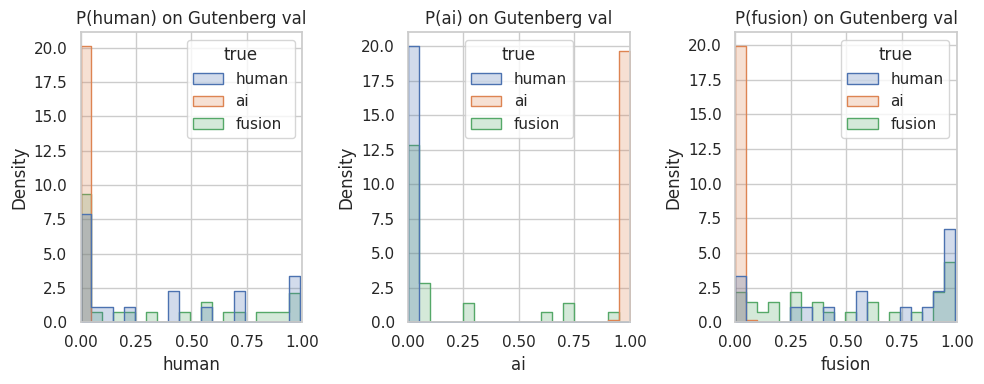

In [10]:
gm = (v[DOMAIN] == GUT).values
print(f"Gutenberg validation rows: {gm.sum()} | labels: {v.loc[gm, LABEL].value_counts().to_dict()}")
print(f"Gutenberg macro-F1 = {f1_score(y_val[gm], val_pred[gm], average='macro'):.4f}\n")
print(classification_report(y_val[gm], val_pred[gm], labels=CLASSES, digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_plot(y_val[gm], val_pred[gm], "Gutenberg: counts", axes[0], normalize=False)
cm_plot(y_val[gm], val_pred[gm], "Gutenberg: row-normalised", axes[1])
plt.tight_layout(); plt.show()

# how confident is the model on Gutenberg minority texts?
gp = pd.DataFrame(val_proba[gm], columns=model.classes_).assign(true=y_val[gm], pred=val_pred[gm])
plt.figure(figsize=(10, 4))
for i, c in enumerate(CLASSES):
    plt.subplot(1, 3, i + 1)
    sns.histplot(data=gp, x=c, hue="true", hue_order=CLASSES, bins=20, element="step", stat="density", common_norm=False)
    plt.title(f"P({c}) on Gutenberg val"); plt.xlim(0, 1)
plt.tight_layout(); plt.show()

## By text length
Long texts are where a fusion insertion can be diluted, and very short texts give the model little to go on.

In [11]:
v["length_bucket"] = pd.qcut(v["n_chars"], 5, duplicates="drop")
len_rows = []
for b, gr in v.groupby("length_bucket", observed=True):
    f1s = f1_score(gr[LABEL], gr["pred"], labels=CLASSES, average=None, zero_division=0)
    len_rows.append({"chars": str(b), "n": len(gr), "macro_f1": f1_score(gr[LABEL], gr["pred"], average="macro"),
                     **{f"f1_{c}": x for c, x in zip(CLASSES, f1s)}})
display(pd.DataFrame(len_rows).style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"],
                                                         cmap="RdYlGn", vmin=0.3, vmax=1).format(precision=3))

,chars,n,macro_f1,f1_human,f1_ai,f1_fusion
0,"(99.999, 1330.0]",4002,0.818,0.744,0.963,0.746
1,"(1330.0, 2419.0]",4002,0.882,0.803,0.989,0.854
2,"(2419.0, 3488.0]",4002,0.901,0.840,0.995,0.868
3,"(3488.0, 4916.4]",3994,0.915,0.867,0.998,0.880
4,"(4916.4, 26025.0]",4000,0.913,0.864,0.998,0.877


## Error examples

In [12]:
err = v[~v["correct"]]
print("most common confusions:")
display(err.groupby([LABEL, "pred"]).size().sort_values(ascending=False).rename("n").to_frame())
print("most errors by domain (share of that domain's validation rows):")
display((err.groupby([LANG, DOMAIN]).size() / v.groupby([LANG, DOMAIN]).size()).dropna().sort_values(ascending=False)
        .round(3).rename("error_rate").to_frame())
for (t, pr), gr in err.groupby([LABEL, "pred"]):
    print(f"\n--- true={t} -> pred={pr} ({len(gr)})")
    for _, row in gr.sample(min(2, len(gr)), random_state=RANDOM_STATE).iterrows():
        print(f"   [{row[LANG]}|{row[DOMAIN]}]", repr(row[TEXT][:220]))
print("\n--- Gutenberg errors")
for _, row in err[err[DOMAIN] == GUT].head(6).iterrows():
    print(f"   true={row[LABEL]} pred={row['pred']} [{row[LANG]}]", repr(row[TEXT][:220]))

most common confusions:


n
label  pred       
fusion human   976
human  fusion  771
fusion ai       86
ai     fusion   55
       human    27
human  ai       19

most errors by domain (share of that domain's validation rows):


error_rate
lang  domain                            
en-EN blog_authorship_corpus       0.232
      student_essays               0.085
de-DE bundestag                    0.080
en-EN house_of_commons             0.077
      euro_court_cases             0.073
      cnn_news                     0.069
      gutenberg                    0.053
      arxiv_papers                 0.018


--- true=ai -> pred=fusion (55)
   [en-EN|student_essays] 'I think anyone considering joining the “Seagoing Cowboys” program should really think twice. It’s way too dangerous! One of the biggest problems is seasickness. I can infer this just from watching documentaries about shi'
   [en-EN|blog_authorship_corpus] 'I certainly agree with the sentiment that terrorism has a long and disturbing history, one often conveniently forgotten by those who use the term so readily today. It seems we’ve become blind to our own actions when it s'

--- true=ai -> pred=human (27)
   [en-EN|house_of_commons] 'I have the honour to inform the House that Royal Assent has been given to the Consolidated Fund Act 2009. This Act is now law.'
   [en-EN|blog_authorship_corpus] 'Dave and his assclown crew are the worst bonk them all fucking idiots ive had enough i swear to god they think theyre better than everyone else like halle berry or somethin ugh.'

--- true=fusion -> pred=ai (86)
   [en-EN|blog_authorship

## Predict test & save submission
Saves `/kaggle/working/submission.csv` (format `id,label`, in `sample_submission.csv` order) and shows a download link. On Kaggle, it also appears under *Output*, where it can be submitted to the competition.

In [13]:
with timer("predict test"):
    test_pred = model.predict(X_test)

sub = sample_sub[["id"]].merge(pd.DataFrame({"id": test["id"].values, "label": test_pred}), on="id", how="left")
assert sub["label"].notna().all() and len(sub) == len(sample_sub) and set(sub["label"]) <= set(CLASSES)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SUB_PATH = OUT_DIR / "submission.csv"
sub.to_csv(SUB_PATH, index=False)
print(f"saved {SUB_PATH.resolve()} {sub.shape} | validation macro-F1 {VAL_MACRO_F1:.4f}")
display(sub.head())
display(pd.concat({"train share": train[LABEL].value_counts(normalize=True),
                   "test pred share": sub["label"].value_counts(normalize=True),
                   "test pred share (gutenberg)": sub.loc[sub["id"].isin(test.loc[test[DOMAIN] == GUT, "id"]), "label"].value_counts(normalize=True)},
                  axis=1).reindex(CLASSES).round(3))

os.chdir(OUT_DIR)            # FileLink paths are relative to the working directory
display(FileLink(SUB_PATH.name))

[start] predict test ...
[done]  predict test: 0.4s
saved /kaggle/working/submission.csv (25000, 2) | validation macro-F1 0.8846


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


,train share,test pred share,test pred share (gutenberg)
label,,,
human,0.245,0.271,0.017
ai,0.448,0.516,0.965
fusion,0.307,0.213,0.018


/kaggle/working/submission.csv